In [183]:
import numpy as np
import matplotlib.pyplot as plt

In [184]:
A = np.array([
    [-1,  1,  1,  1, -1],
    [ 1, -1, -1, -1,  1],
    [ 1,  1,  1,  1,  1],
    [ 1, -1, -1, -1,  1],
    [ 1, -1, -1, -1,  1]
])

Z = np.array([
    [ 1,  1,  1,  1,  1],
    [-1, -1, -1,  1, -1],
    [-1, -1,  1, -1, -1],
    [-1,  1, -1, -1, -1],
    [ 1,  1,  1,  1,  1]
])

def gen_random(size):
    return np.random.choice([-1, 1], size=(size, size))

# plt.imshow(A)
# plt.show()
# plt.imshow(Z)
# plt.show()

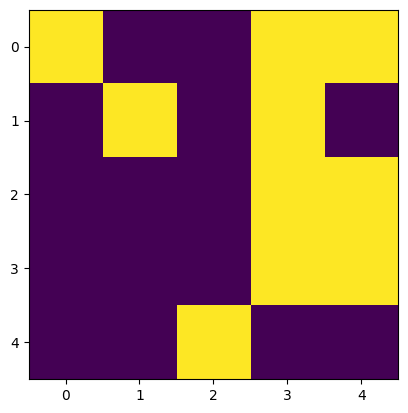

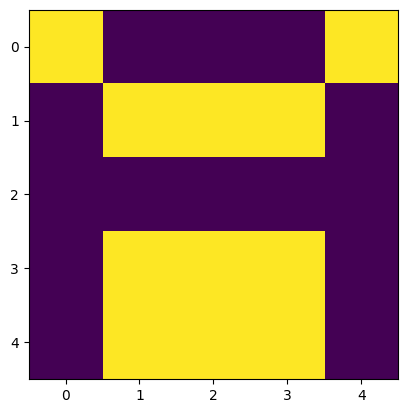

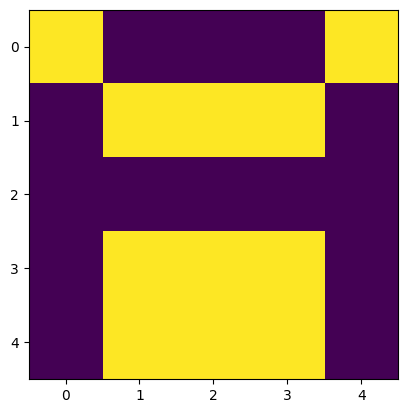

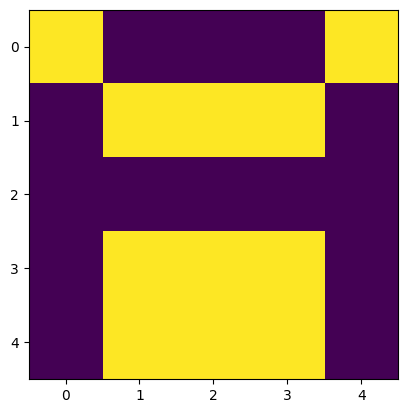

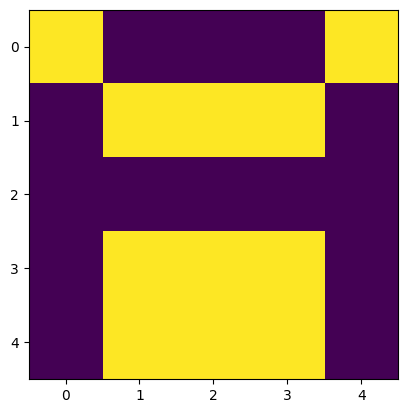

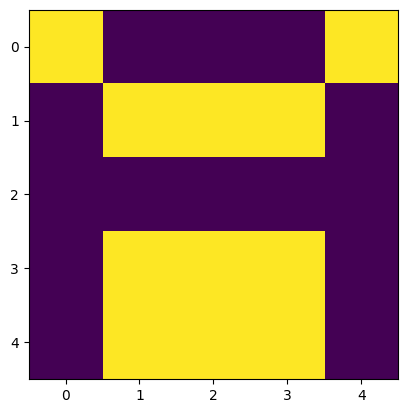

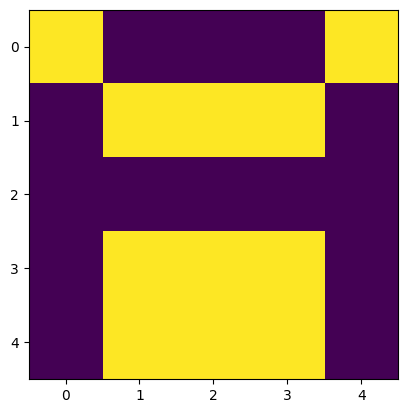

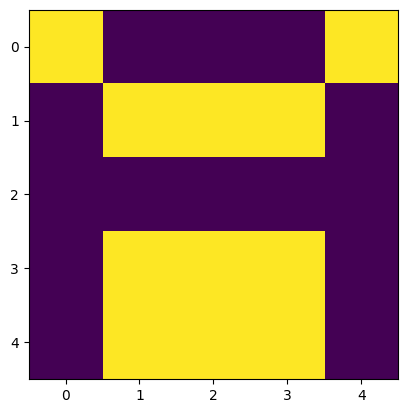

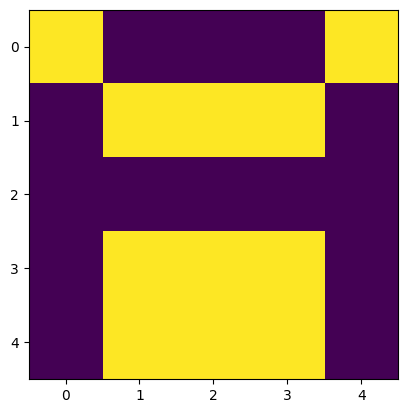

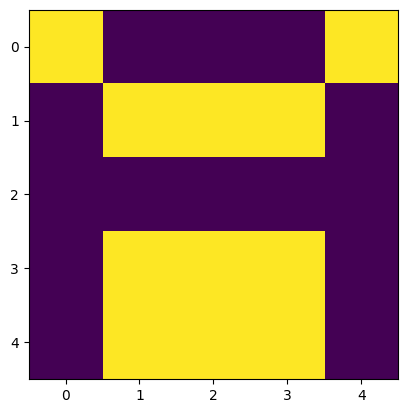

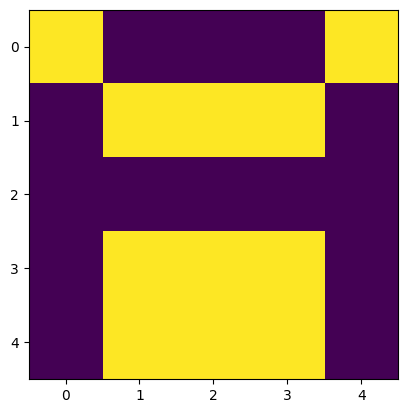

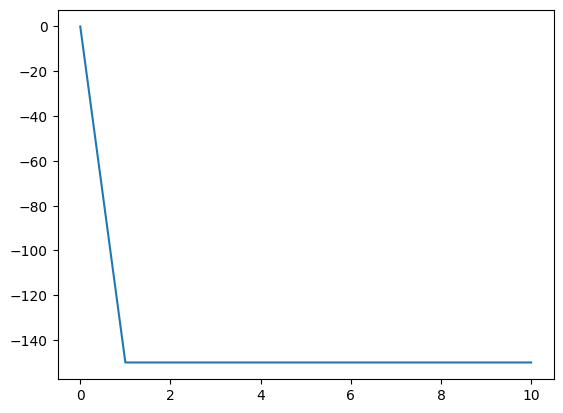

array([[ 1., -1., -1., -1.,  1.],
       [-1.,  1.,  1.,  1., -1.],
       [-1., -1., -1., -1., -1.],
       [-1.,  1.,  1.,  1., -1.],
       [-1.,  1.,  1.,  1., -1.]])

In [185]:
def Hebb(list_of_matirces):
    n = len(list_of_matirces)
    shape = list_of_matirces[0].shape
    dimension = list_of_matirces[0].size

    w = np.zeros((dimension, dimension), dtype=float)
    for m in list_of_matirces:
        v = m.reshape(dimension, 1)  # (25×1)
        w += (v @ v.T) / n

    np.fill_diagonal(w, 0)
    return w

def Hamiltonian(s, w):
    dimension = s.size
    s = s.reshape(dimension, 1)

    return -0.5 * (s.T @ w @ s).item() 

def Hebb_transform(input, w, iterations, verbose=False):
    dimension = input.size
    shape = input.shape
    input = input.reshape(dimension, 1)
    hamiltonian = []
    hamiltonian.append(Hamiltonian(input, w))
    if verbose:
        plt.imshow(input.reshape(shape))
        plt.show()

    for i in range(iterations):
        input = np.sign(w @ input)
        hamiltonian.append(Hamiltonian(input, w))
        if verbose or i == iterations-1:
            plt.imshow(input.reshape(shape))
            plt.show()
    input = input.reshape(shape)

    if verbose:
        plt.plot(hamiltonian)
        plt.show()

    return input
    
def Hebb_transform_async(x, w, iterations):
    shape = x.shape
    x = x.reshape(-1, 1)
    N = x.shape[0]

    for _ in range(iterations):
        for i in np.random.permutation(N):
            h = w[i, :] @ x
            x[i] = 1 if h >= 0 else -1

    x = x.reshape(shape)
    plt.imshow(x)
    plt.show()
    
    return x


w = Hebb((A, Z))

Hebb_transform(gen_random(5), w, 10, True)

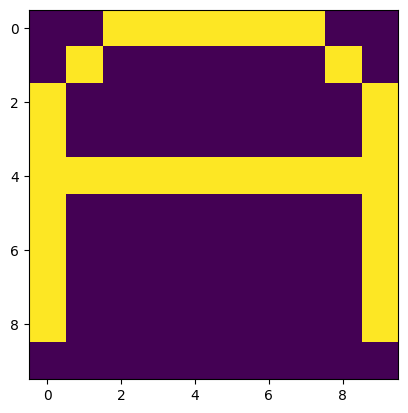

In [186]:
import numpy as np

# 1 = filled pixel, -1 = empty pixel

A = np.array([
[-1,-1,1,1,1,1,1,1,-1,-1],
[-1,1,-1,-1,-1,-1,-1,-1,1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,1,1,1,1,1,1,1,1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[-1,-1,-1,-1,-1,-1,-1,-1,-1,-1]
])

b = np.array([
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,1,1,1,1,1,1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,1,-1],
[1,1,1,1,1,1,1,-1,-1,-1],
[-1,-1,-1,-1,-1,-1,-1,-1,-1,-1]
])

C = np.array([
[-1,1,1,1,1,1,1,1,1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[-1,1,1,1,1,1,1,1,1,-1]
])

d = np.array([
[-1,-1,-1,-1,-1,-1,-1,-1,1,-1],
[-1,-1,-1,-1,-1,-1,-1,-1,1,-1],
[-1,-1,-1,-1,-1,-1,-1,-1,1,-1],
[-1,-1,1,1,1,1,1,1,1,-1],
[-1,1,-1,-1,-1,-1,-1,-1,1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,1,-1],
[-1,1,-1,-1,-1,-1,-1,-1,1,-1],
[-1,-1,1,1,1,1,1,1,-1,-1]
])

E = np.array([
[1,1,1,1,1,1,1,1,1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,1,1,1,1,1,1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,1,1,1,1,1,1,1,1,1]
])

f = np.array([
[-1,1,1,1,1,1,1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,1,1,1,1,1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[-1,-1,-1,-1,-1,-1,-1,-1,-1,-1]
])

G = np.array([
[-1,1,1,1,1,1,1,1,1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,1,1,1,1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[-1,1,1,1,1,1,1,1,1,-1]
])

h = np.array([
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,1,1,1,1,1,1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,1,-1],
[1,-1,-1,-1,-1,-1,-1,1,-1,-1],
[1,-1,-1,-1,-1,-1,1,-1,-1,-1]
])

I = np.array([
[-1,-1,1,1,1,1,1,1,-1,-1],
[-1,-1,-1,1,1,1,1,-1,-1,-1],
[-1,-1,-1,1,1,1,1,-1,-1,-1],
[-1,-1,-1,1,1,1,1,-1,-1,-1],
[-1,-1,-1,1,1,1,1,-1,-1,-1],
[-1,-1,-1,1,1,1,1,-1,-1,-1],
[-1,-1,-1,1,1,1,1,-1,-1,-1],
[-1,-1,-1,1,1,1,1,-1,-1,-1],
[-1,-1,-1,1,1,1,1,-1,-1,-1],
[-1,-1,1,1,1,1,1,1,-1,-1]
])

j = np.array([
[-1,-1,-1,-1,1,1,1,1,1,-1],
[-1,-1,-1,-1,-1,-1,1,1,-1,-1],
[-1,-1,-1,-1,-1,-1,1,1,-1,-1],
[-1,-1,-1,-1,-1,-1,1,1,-1,-1],
[-1,-1,-1,-1,-1,-1,1,1,-1,-1],
[-1,-1,-1,-1,-1,-1,1,1,-1,-1],
[1,-1,-1,-1,-1,-1,1,1,-1,-1],
[1,-1,-1,-1,-1,-1,1,1,-1,-1],
[1,-1,-1,-1,-1,-1,1,1,-1,-1],
[-1,1,1,1,1,1,1,-1,-1,-1]
])


X = np.array([
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[-1,1,-1,-1,-1,-1,-1,-1,1,-1],
[-1,-1,1,-1,-1,-1,-1,1,-1,-1],
[-1,-1,-1,1,-1,-1,1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,1,-1,-1,1,-1,-1,-1],
[-1,-1,1,-1,-1,-1,-1,1,-1,-1],
[-1,1,-1,-1,-1,-1,-1,-1,1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1]
])

O = np.array([
[-1,1,1,1,1,1,1,1,1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[-1,1,1,1,1,1,1,1,1,-1]
])

T = np.array([
[1,1,1,1,1,1,1,1,1,1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1]
])

S = np.array([
[-1,1,1,1,1,1,1,1,1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[-1,1,1,1,1,1,1,1,1,-1],
[-1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[-1,-1,-1,-1,-1,-1,-1,-1,1,-1],
[-1,-1,-1,-1,-1,-1,-1,1,-1,-1],
[-1,-1,-1,-1,-1,-1,1,-1,-1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,1,1,1,1,1,1,1,1,-1]
])

Z = np.array([
[1,1,1,1,1,1,1,1,1,1],
[-1,-1,-1,-1,-1,-1,-1,-1,1,-1],
[-1,-1,-1,-1,-1,-1,-1,1,-1,-1],
[-1,-1,-1,-1,-1,-1,1,-1,-1,-1],
[-1,-1,-1,-1,-1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,-1,-1,-1,-1,-1],
[-1,-1,-1,1,-1,-1,-1,-1,-1,-1],
[-1,-1,1,-1,-1,-1,-1,-1,-1,-1],
[-1,1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,1,1,1,1,1,1,1,1,1]
])

plus = np.array([
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[1,1,1,1,1,1,1,1,1,1],
[1,1,1,1,1,1,1,1,1,1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1]
])

diag = np.array([
[1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[-1,1,-1,-1,-1,-1,-1,-1,-1,-1],
[-1,-1,1,-1,-1,-1,-1,-1,-1,-1],
[-1,-1,-1,1,-1,-1,-1,-1,-1,-1],
[-1,-1,-1,-1,1,-1,-1,-1,-1,-1],
[-1,-1,-1,-1,-1,1,-1,-1,-1,-1],
[-1,-1,-1,-1,-1,-1,1,-1,-1,-1],
[-1,-1,-1,-1,-1,-1,-1,1,-1,-1],
[-1,-1,-1,-1,-1,-1,-1,-1,1,-1],
[-1,-1,-1,-1,-1,-1,-1,-1,-1,1]
])

frame = np.array([
[1,1,1,1,1,1,1,1,1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,-1,1,-1,-1,-1,-1,1,-1,1],
[1,-1,-1,1,-1,-1,1,-1,-1,1],
[1,-1,-1,-1,1,1,-1,-1,-1,1],
[1,-1,-1,-1,1,1,-1,-1,-1,1],
[1,-1,-1,1,-1,-1,1,-1,-1,1],
[1,-1,1,-1,-1,-1,-1,1,-1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,1,1,1,1,1,1,1,1,1]
])

cross = np.array([
[-1,1,-1,-1,-1,-1,-1,-1,1,-1],
[-1,-1,1,-1,-1,-1,-1,1,-1,-1],
[-1,-1,-1,1,-1,-1,1,-1,-1,-1],
[-1,-1,-1,-1,1,1,-1,-1,-1,-1],
[-1,-1,-1,1,-1,-1,1,-1,-1,-1],
[-1,-1,1,-1,-1,-1,-1,1,-1,-1],
[-1,1,-1,-1,-1,-1,-1,-1,1,-1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[-1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[-1,-1,-1,-1,-1,-1,-1,-1,-1,-1]
])

dash = np.array([
[-1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[-1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[-1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[1,1,1,1,1,1,1,1,1,1],
[1,1,1,1,1,1,1,1,1,1],
[-1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[-1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[-1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[-1,-1,-1,-1,-1,-1,-1,-1,-1,-1],
[-1,-1,-1,-1,-1,-1,-1,-1,-1,-1]
])

M = np.array([
[1,-1,-1,-1,-1,-1,-1,-1,-1,1],
[1,1,-1,-1,-1,-1,-1,-1,1,1],
[1,-1,1,-1,-1,-1,-1,1,-1,1],
[1,-1,-1,1,-1,-1,1,-1,-1,1],
[1,-1,-1,-1,1,1,-1,-1,-1,1],
[1,-1,-1,-1,1,1,-1,-1,-1,1],
[1,-1,-1,1,-1,-1,1,-1,-1,1],
[1,-1,1,-1,-1,-1,-1,1,-1,1],
[1,1,-1,-1,-1,-1,-1,-1,1,1],
[1,-1,-1,-1,-1,-1,-1,-1,-1,1]
])

patterns = (A, b, C, d, E, f, G, h, I, j, X, O, T, S, Z, plus, diag, frame, cross, dash)
plt.imshow(A)

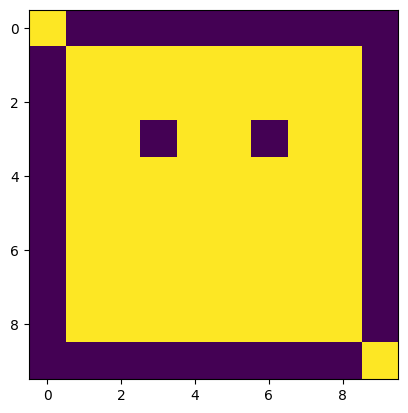

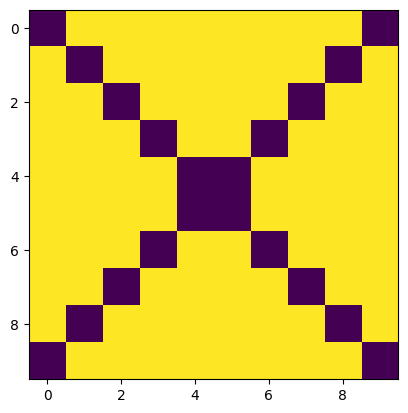

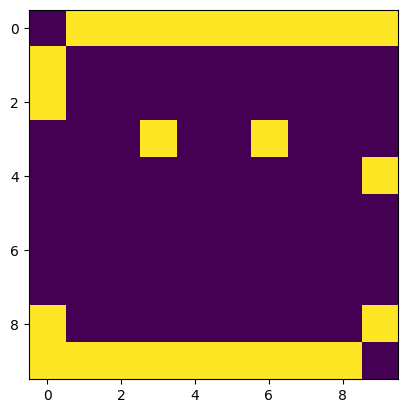

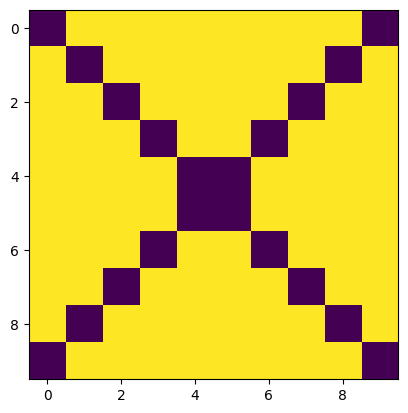

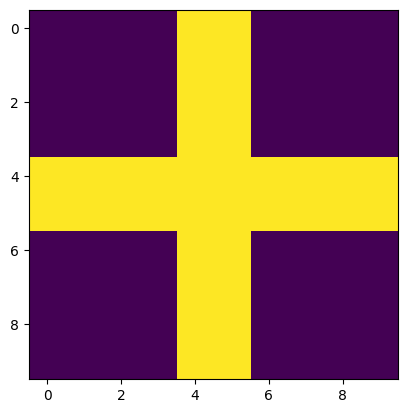

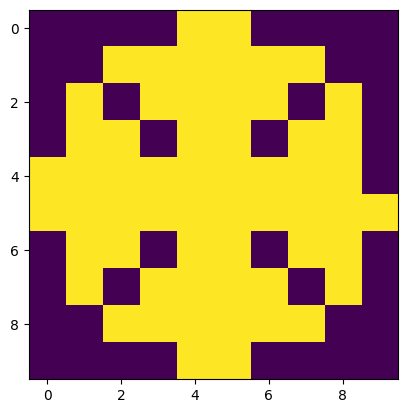

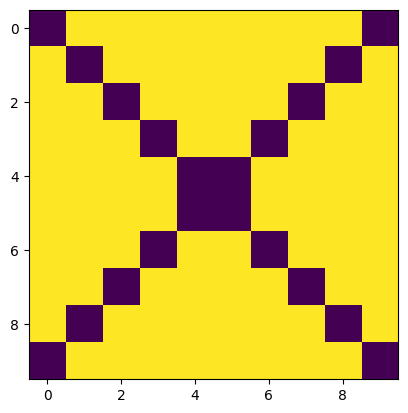

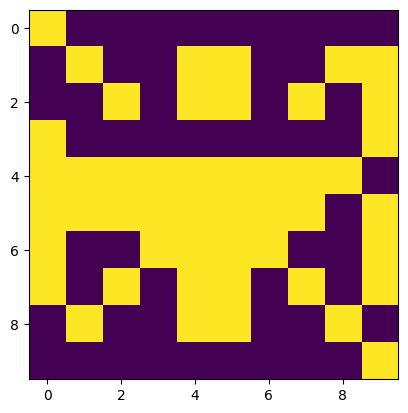

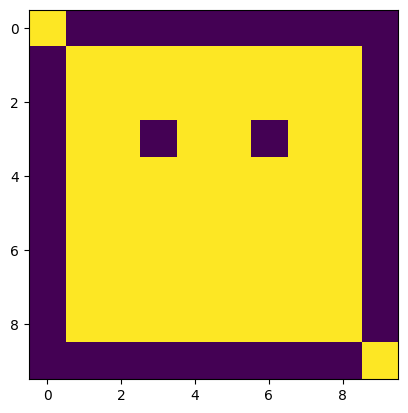

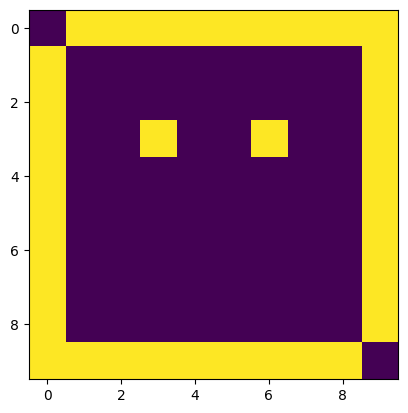

In [187]:
w = Hebb((O, X, S, M, plus))

for _ in range(10):
    Hebb_transform(gen_random(10), w, 64)
